## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [2]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import levene, ttest_ind, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest


In [3]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [4]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [5]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


In [36]:
# Convertir la fecha al tipo datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

**Hallazgos en la calidad de los datos**

El conjunto contiene 40,000 registros y 9 columnas.
No se identificaron valores nulos.
Se convierten las siguientes variables:
- `date` : object -> formato datetime (para facilitar análisis)
  
De ahi en más, no se requieren imputaciones ni eliminación de registros por problemas de calidad detectados.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [7]:
# Verificar identificadores únicos y duplicados
print("Usuarios únicos:", df["user_id"].nunique())
print("Registros duplicados:", df.duplicated().sum())
print("Identificadores repetidos:", df["user_id"].duplicated().sum())

Usuarios únicos: 40000
Registros duplicados: 0
Identificadores repetidos: 0


 **Variable `date`**  
Explorar rango de fechas

In [37]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [9]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [10]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [38]:
# Resumen estadístico de usuarios que se convirtieron
df.loc[df["converted"] == 1, "gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [13]:
for col in ["landing","region","dispositivo","traffic_source","user_type","converted"]:
    print(f"\n{col}:")
    print(df[col].value_counts())



landing:
B    20018
A    19982
Name: landing, dtype: int64

region:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

converted:
0    34294
1     5706
Name: converted, dtype: int64


### Hallazgos de variables categóricas
Las versiones observadas son A y B; `converted` contiene únicamente 0 y 1. Las categorías de región, dispositivo, fuente de tráfico y tipo de usuario son consistentes. La asignación está prácticamente equilibrada: **19,982 usuarios en A y 20,018 en B**. No se encontraron valores nulos ni gastos negativos. Se puede continuar con las comparaciones estadísticas.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [14]:
# Gasto por versión
gasto_A = df.loc[(df["landing"] == "A") & (df["converted"] == 1), "gasto"].dropna()
gasto_B = df.loc[(df["landing"] == "B") & (df["converted"] == 1), "gasto"].dropna()

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [39]:
# Estadísticas descriptivas del gasto por versión
resumen_gasto = df[df["converted"] == 1].groupby("landing")["gasto"].agg(
    usuarios_convertidos="count", gasto_promedio="mean", mediana="median", desviacion="std"
)
resumen_gasto


,usuarios_convertidos,gasto_promedio,mediana,desviacion
landing,,,,
A,2512,61.086572,55.84,28.87547
B,3194,68.745360,62.57,32.00102


### Prueba T de Welch

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios convertidos es igual en las versiones A y B.
- **Hipótesis alternativa (H₁):** El gasto promedio de los  usuarios convertidos es diferente en las versiones A y B.

Se aplicó inicialmente la prueba de Levene para evaluar la igualdad de varianzas entre los grupos A y B. Los resultados indicaron diferencias estadísticamente significativas entre las varianzas (p-valor menor a 0.05).

Por esta razón, se seleccionó la prueba t de Welch para comparar el gasto promedio de los usuarios convertidos, ya que no requiere asumir igualdad de varianzas.

In [15]:
# Ejecutar prueba de Levene y mostrar resultados
l_stat, p_value_var = levene(gasto_A, gasto_B)
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")

alpha = 0.05  # umbral de significancia
if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")

Estadístico de Levene: 29.17646453202917
Valor p: 6.875301988016449e-08
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).


In [16]:
# Aplicar prueba T de Welch
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat:.4f}")
print(f"Valor p: {p_value:.4e}")

Estadístico : -9.4810
Valor p: 3.6276e-21


In [17]:
if p_value < 0.05:
    print("Existe diferencia significativa entre las medias.")
else:
    print("No existe diferencia significativa entre las medias.")


Existe diferencia significativa entre las medias.


In [40]:
# Diferencia porcentual del gasto promedio B respecto a A
media_A, media_B = gasto_A.mean(), gasto_B.mean()
diferencia = media_B - media_A
variacion_pct = (diferencia / media_A) * 100
print(f"Promedio A: ${media_A:.2f}")
print(f"Promedio B: ${media_B:.2f}")
print(f"Diferencia B - A: ${diferencia:.2f} ({variacion_pct:.2f}%)")

Promedio A: $61.09
Promedio B: $68.75
Diferencia B - A: $7.66 (12.54%)


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza H₀ porque el valor p es menor que 0.05 (t = -9.481; p = 3.63 × 10⁻²¹).

**Interpretación de negocio:**  
Entre los usuarios que realizaron una conversión, la versión A registra un gasto promedio de **61.09**, mientras que B registra **68.75**. La diferencia es de **7.66**, equivalente a aproximadamente **12.54% más en B**. Existe evidencia estadística de una diferencia en el gasto promedio, a favor de B. Este resultado se refiere únicamente a compradores convertidos; no representa por sí solo el ingreso por visitante.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z para comparar proporciones

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en A y B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente en A y B.

In [18]:
# Número de usuarios convertidos por página
conversiones = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [19]:
# Pasar los valores a formato lista
exitos = [conversiones['A'], conversiones['B']]
observaciones = [totales['A'], totales['B']]

In [20]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos , observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22


### 📝 Conclusión e interpretación

**Decisión:**  
Rechazamos la hipótesis nula: hay evidencia de una diferencia.

**Interpretación de negocio:**  
A convierte **12.57%** de sus visitantes y B convierte **15.96%**. La diferencia es de **3.38 puntos porcentuales**, o aproximadamente **26.92% de mejora relativa** en B. La versión B genera una mayor proporción de usuarios convertidos; por cada 1,000 visitantes representa alrededor de 34 conversiones adicionales.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi-cuadrado de independencia

**Hipótesis:**

- **Hipótesis nula (H₀):** No hay relación entre la fuentre de tráfico y la conversión.
- **Hipótesis alternativa (H₁):** Existe relación entre la fuente de tráfico y la conversión.


In [21]:
# Tabla de contingencia normalizada
print(pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100)

# Tabla de contingencia para prueba Chi2
tabla = pd.crosstab( df["traffic_source"], df["converted"])

tabla

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163


converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [22]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

In [23]:
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]


### 📝 Conclusión e interpretación ###

**Decisión:**  
Se rechaza H₀ porque el valor p es menor que 0.05 (chi-cuadrado = 8.662; p = 0.034). Existe evidencia estadísticamente significativa de una asociación entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**  
Email presenta la mayor tasa de conversión (14.99%), seguido de Ads (14.74%), Referral (13.88%) y Organic (13.79%). Sin embargo, Organic genera el mayor volumen de conversiones (2,480), seguido de Ads (1,759), Email (918) y Referral (549), debido a que concentra una mayor cantidad de visitantes.



## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi-cuadrado de independencia

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay relación entre el tipo de usuario y la conversión.
- **Hipótesis alternativa (H₁):** Existe relación entre el tipo de usuario y la conversión.


In [24]:
# Tabla de contingencia normalizada
print(pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100)

# Tabla de contingencia para prueba Chi2
tabla = pd.crosstab( df["user_type"], df["converted"])

tabla

converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [25]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

In [26]:
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza H₀ (χ² = 0.5135; p = 0.4736). No hay evidencia estadística suficiente de asociación entre tipo de usuario y conversión.

**Interpretación de negocio:**  
Los usuarios nuevos presentan una tasa de conversión ligeramente superior (14.36%) en comparación con los usuarios recurrentes (14.09%). Sin embargo, la diferencia es de apenas 0.27 puntos porcentuales y no resulta estadísticamente significativa. Los usuarios nuevos generan el mayor volumen de conversiones (3,738), frente a los recurrentes (1,968), principalmente porque representan una mayor cantidad de visitantes.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

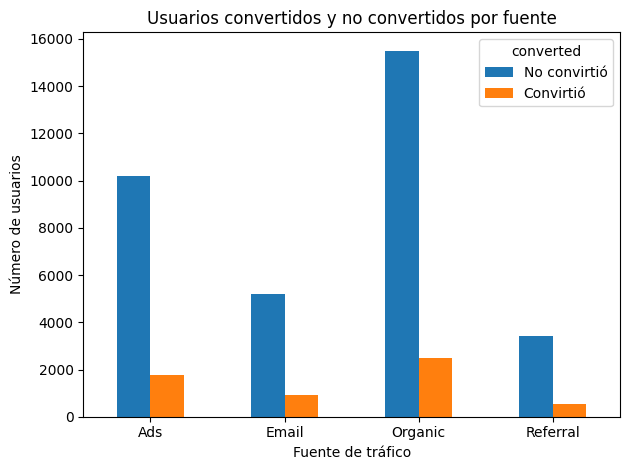

In [27]:
# Cantidad absoluta de conversiones y no conversiones por fuente
conteo_trafico = pd.crosstab(df["traffic_source"], df["converted"]).rename(columns={0: "No convirtió", 1: "Convirtió"})
ax = conteo_trafico.plot(kind="bar")
ax.set_title("Usuarios convertidos y no convertidos por fuente")
ax.set_xlabel("Fuente de tráfico")
ax.set_ylabel("Número de usuarios")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

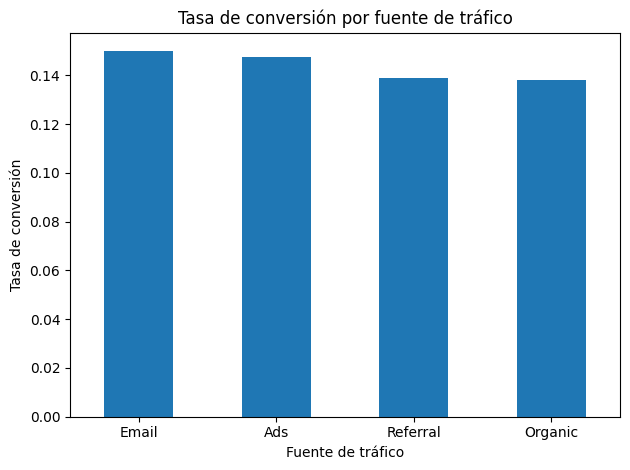

In [28]:
# Proporción de conversión por fuente de tráfico
tasas_fuente = df.groupby("traffic_source")["converted"].mean().sort_values(ascending=False)
ax = tasas_fuente.plot(kind="bar", rot=0)
ax.set_title("Tasa de conversión por fuente de tráfico")
ax.set_xlabel("Fuente de tráfico")
ax.set_ylabel("Tasa de conversión")
plt.tight_layout()
plt.show()

### Interpretación del gráfico: fuente de tráfico
El **gráfico de cantidades** muestra que **Organic** concentra el mayor número de usuarios y conversiones, mientras que el **gráfico de tasas** permite comparar la efectividad relativa de los canales. **Email** y **Ads** presentan las tasas más altas, aunque las diferencias son pequeñas. El resultado Chi-cuadrado detecta asociación global. Por ello, conviene optimizar y monitorear los canales sin atribuirles un efecto grande sobre la conversión.

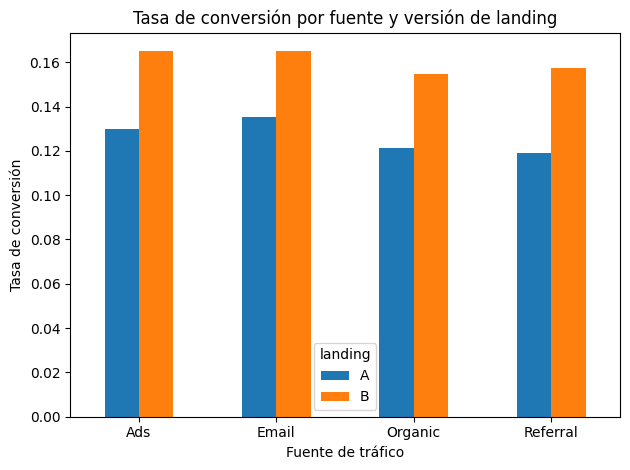

In [29]:
# Comparación de tasa de conversión por fuente y versión
tasas_fuente_version = df.groupby(["traffic_source", "landing"])["converted"].mean().unstack("landing")
ax = tasas_fuente_version.plot(kind="bar")
ax.set_title("Tasa de conversión por fuente y versión de landing")
ax.set_xlabel("Fuente de tráfico")
ax.set_ylabel("Tasa de conversión")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretación del gráfico: fuente y versión

La versión B muestra una tasa de conversión superior a A en las cuatro fuentes de tráfico. Esto sugiere que la mejora observada en B no está limitada visualmente a un solo canal. No obstante, esta comparación descriptiva no sustituye una prueba formal de interacción entre versión y fuente; no permite afirmar que el incremento sea estadísticamente distinto entre canales.

### Relación entre el tipo de usuario y la conversión

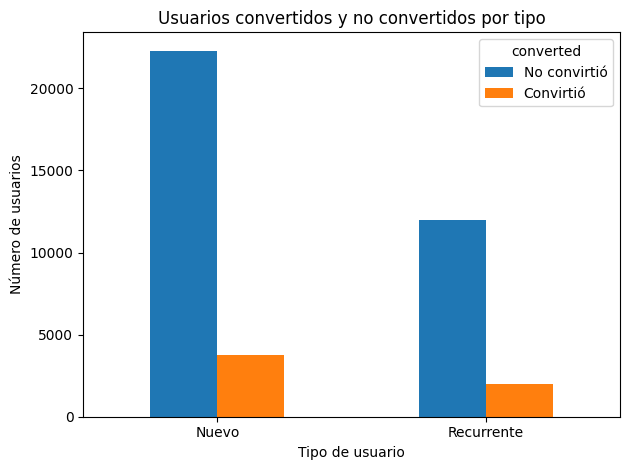

In [30]:
# Cantidad absoluta de conversiones y no conversiones por tipo de usuario
conteo_usuario = pd.crosstab(df["user_type"], df["converted"]).rename(columns={0: "No convirtió", 1: "Convirtió"})
ax = conteo_usuario.plot(kind="bar")
ax.set_title("Usuarios convertidos y no convertidos por tipo")
ax.set_xlabel("Tipo de usuario")
ax.set_ylabel("Número de usuarios")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

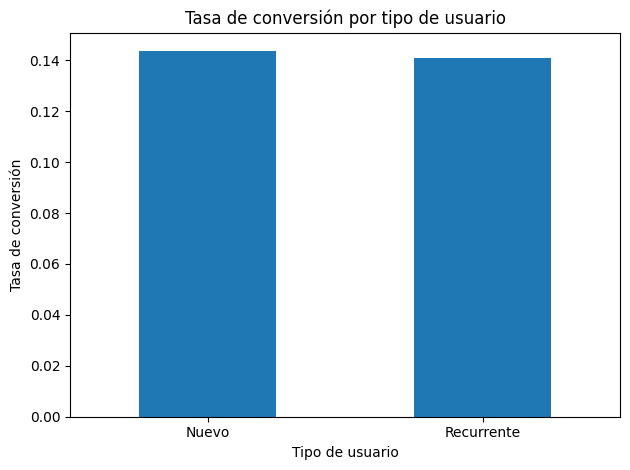

In [31]:
# Tasa de conversión por tipo de usuario
tasas_tipo = df.groupby("user_type")["converted"].mean()
ax = tasas_tipo.plot(kind="bar", rot=0)
ax.set_title("Tasa de conversión por tipo de usuario")
ax.set_xlabel("Tipo de usuario")
ax.set_ylabel("Tasa de conversión")
plt.tight_layout()
plt.show()


### Interpretación del gráfico: tipo de usuario

Los usuarios nuevos representan un mayor volumen de visitantes y conversiones, pero también constituyen el grupo más grande. Al comparar tasas, nuevos y recurrentes presentan resultados muy similares (14.36% y 14.09%). Esto coincide con la prueba Chi-cuadrado, que no detectó una asociación estadísticamente significativa.

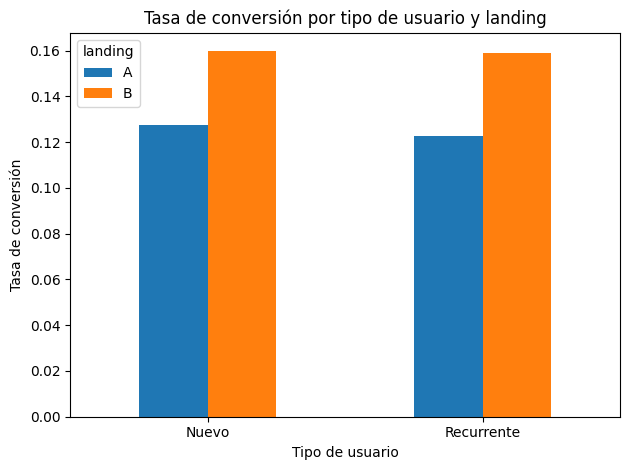

In [32]:
# Tasa de conversión por tipo de usuario y versión
tasas_tipo_version = df.groupby(["user_type", "landing"])["converted"].mean().unstack("landing")
ax = tasas_tipo_version.plot(kind="bar")
ax.set_title("Tasa de conversión por tipo de usuario y landing")
ax.set_xlabel("Tipo de usuario")
ax.set_ylabel("Tasa de conversión")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [33]:
# Tabla comparativa de segmentos por versión
comparacion_segmentos = df.groupby(["landing", "user_type"])["converted"].agg(
    usuarios="count", conversiones="sum", tasa_conversion="mean"
)
comparacion_segmentos


usuarios  conversiones  tasa_conversion
landing user_type                                          
A       Nuevo          12992          1654         0.127309
        Recurrente      6990           858         0.122747
B       Nuevo          13041          2084         0.159804
        Recurrente      6977          1110         0.159094

### Interpretación del gráfico: tipo de usuario y versión

La versión B supera a A tanto en usuarios nuevos como recurrentes. Las tasas de B son aproximadamente 15.98% para nuevos y 15.91% para recurrentes. La mejora de B se observa en ambos segmentos, mientras que la diferencia entre tipos de usuario dentro de cada versión es mínima. Estos resultados respaldan mantener B para ambos perfiles, sin necesidad de personalizar la landing por tipo de usuario con la evidencia disponible.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- A: **\\$61.09** (2,512 usuarios convertidos).
- B: **\\$68.75** (3,194 usuarios convertidos), un **12.54% más** que A.
- La prueba t de Welch detectó una diferencia significativa (t = -9.481; p = 3.63 × 10⁻²¹).
- **Interpretación:** B genera un gasto promedio mayor entre quienes compran.

<br>

**Tasa de conversión:** 
- A: **12.57%** (2,512 / 19,982).
- B: **15.96%** (3,194 / 20,018), una mejora de **3.38 puntos porcentuales** o **26.92% relativa**.
- La prueba Z detectó una diferencia significativa (Z = -9.677; p = 3.76 × 10⁻²²).
  
- **Interpretación:** B convierte una proporción mayor de visitantes.

---

#### 📊 **Segmentación por fuente de tráfico**
- Tasas: Email **14.99%**, Ads **14.74%**, Referral **13.88%** y Organic **13.79%**. Organic tiene el mayor volumen absoluto de conversiones (2,480).
- Chi-cuadrado: p = **0.0341**.

- **Interpretación:** Existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión. Email presenta la mayor tasa de conversión, mientras que Organic genera el mayor volumen de conversiones debido a que concentra más visitantes. Una tasa alta y un volumen alto son conceptos distintos. 
 ---

#### 📊 **Segmentación por tipo de usuario**
- Nuevo: **14.36%**; recurrente: **14.09%**.
- Chi-cuadrado: p = **0.4736**.

- **Interpretación:** No hay evidencia de una asociación entre tipo de usuario y conversión.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 

1. - **Implementar la versión B**, ya que presenta mejoras estadísticamente significativas en la tasa de conversión (+26.92% relativa) y en el gasto promedio de los usuarios que realizan una compra (+12.54%).

2. Monitorear el desempeño económico después de implementar B, utilizando el ingreso promedio por visitante, el margen de contribución y la rentabilidad para evaluar su impacto real en el negocio.

3. Optimizar los canales de adquisición: Email presenta la mayor tasa de conversión (14.99%), mientras que Organic genera el mayor volumen de conversiones (2,480). Se recomienda evaluar ambos canales considerando también sus costos de adquisición.

4. Mantener una experiencia consistente para usuarios nuevos y recurrentes, ya que no se encontró evidencia estadísticamente significativa de una asociación entre el tipo de usuario y la conversión.

5. Realizar un nuevo experimento A/B para identificar qué elementos de diseño o contenido de la versión B contribuyen a mejorar la conversión y el gasto promedio.

**Conclusión:**
Se recomienda implementar la versión B debido a sus mejores resultados en conversión y gasto promedio por comprador, manteniendo un seguimiento de los indicadores económicos para validar su impacto en la rentabilidad del negocio